In [2]:
#!/usr/bin/env python
# coding: utf-8

# In[1]:


import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import json
import sys
from scipy.special import beta as beta_func
import matplotlib


from inversion import estimate_beta_tinti, round_half_up, parameter_array2dict,\
    parameter_dict2array, to_days, branching_ratio

from shapely.geometry import Polygon

from simulation import generate_catalog



fn_store = 'my_synthetic_catalog'
shape_coords = [list([a[1], a[0]]) for a in (np.load("california_shape.npy"))]
caliregion = Polygon(shape_coords)
burn_start = dt.datetime(1871, 1, 1)
primary_start = dt.datetime(1971, 1, 1)
end = dt.datetime(2021, 1, 1)


delta_m = 0.1
mc = 3.6

beta_const = np.log(10)


parameters = {
    'log10_mu': -7.17,
    'log10_k0': -2.49,
    'a': 1.69,
    'log10_c': -2.95,
    'omega': 0.12,
    'log10_tau': 3.99,
    'log10_d': -0.35,
    'gamma': 1.22,
    'rho': 0.51
}


synthetic = generate_catalog(
    polygon=caliregion,
    timewindow_start=start,
    timewindow_end=end,
    parameters=parameters,
    mc=mc,
    beta_main=beta_const,
    delta_m=delta_m
)

NameError: name 'start' is not defined

In [9]:
synthetic.magnitude = round_half_up(synthetic.magnitude, 1)
synthetic.index.name = 'id'
synthetic[["latitude", "longitude", "time", "magnitude"]].query("time>=@aux_start").to_csv(fn_store)

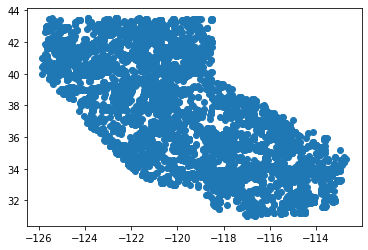

In [3]:
plt.scatter(synthetic.query("time>=@aux_start").longitude, synthetic.query("time>=@aux_start").latitude)

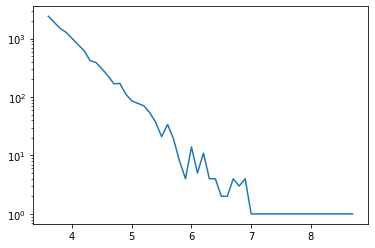

In [4]:
plt.plot(*np.unique(synthetic.query("time>=@aux_start").magnitude, return_counts=True))
plt.yscale("log")

In [18]:
sc = pd.read_csv("synthetic_catalog.csv", index_col=0, parse_dates=["time"])

In [19]:
estimate_beta_tinti(sc.magnitude, mc=3.6, delta_m=0.1)/np.log(10)

1.0066840767004368

In [173]:
fn_store = 'my_synthetic_catalog.csv'
shape_coords = np.load("california_shape.npy")
caliregion = Polygon(shape_coords)
burn_start = dt.datetime(1871, 1, 1)
primary_start = dt.datetime(1971, 1, 1)
end = dt.datetime(2021, 1, 1)

delta_m = 0.1
mc = 3.6
beta = np.log(10)

parameters = {
    'log10_mu': -7.5,
    'log10_k0': -2.49,
    'a': 1.69,
    'log10_c': -2.95,
    'omega': 0.01,
    'log10_tau': 3.99,
    'log10_d': -0.35,
    'gamma': 1.22,
    'rho': 0.51
}

# np.random.seed(777)

synthetic = generate_catalog(
    polygon=caliregion,
    timewindow_start=burn_start,
    timewindow_end=end,
    parameters=parameters,
    mc=mc,
    beta_main=beta,
    delta_m=delta_m
)

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
/usr/local/lib/python3.8/site-packages/shapely/ops.py:240: DeprecationWarning: This function is deprecated. See: https://pyproj4.github.io/pyproj/stable/gotchas.html#upgrading-to-pyproj-2-from-pyproj-1
  zip(*func(*izip(*geom.exterior.coords))))


generating background events..


/usr/local/lib/python3.8/site-packages/shapely/ops.py:240: DeprecationWarning: This function is deprecated. See: https://pyproj4.github.io/pyproj/stable/gotchas.html#upgrading-to-pyproj-2-from-pyproj-1
  zip(*func(*izip(*geom.exterior.coords))))


  number of background events needed: 1680
  generating 3420 to throw away those outside the polygon
  number of background events: 1680

  branching ratio: 0.8561870086713119
  expected total number of events (if time were infinite): 11681.837534137088


simulating aftershocks of generation 0 ..
  number of events with aftershocks: 882
  number of generated aftershocks: 1359


simulating aftershocks of generation 1 ..
  number of events with aftershocks: 693
  number of generated aftershocks: 1063


simulating aftershocks of generation 2 ..
  number of events with aftershocks: 524
  number of generated aftershocks: 813


simulating aftershocks of generation 3 ..
  number of events with aftershocks: 413
  number of generated aftershocks: 641


simulating aftershocks of generation 4 ..
  number of events with aftershocks: 334
  number of generated aftershocks: 548


simulating aftershocks of generation 5 ..
  number of events with aftershocks: 278
  number of generated aftershocks: 433


In [174]:
from simulation import expected_aftershocks

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [175]:
theta_without_mu = parameters["log10_k0"], parameters["a"], parameters["log10_c"], parameters["omega"], \
                       parameters["log10_tau"], parameters["log10_d"], parameters["gamma"], parameters["rho"]

np.random.poisson(lam=expected_aftershocks(
    np.ones(300)*3,
    params=[theta_without_mu, mc - delta_m / 2],
    no_start=True,
    no_end=True,
    # axis=1
)).sum()

70

In [177]:
from simulation import generate_background_events

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [178]:
beta_aftershock = beta

# generate background events
print("generating background events..")
catalog = generate_background_events(
    caliregion, burn_start, end, parameters, beta=beta, mc=mc, delta_m=delta_m
)

theta = parameters["log10_mu"], parameters["log10_k0"], parameters["a"], parameters["log10_c"], parameters["omega"], \
        parameters["log10_tau"], parameters["log10_d"], parameters["gamma"], parameters["rho"]
br = branching_ratio(theta, beta)

print('  number of background events:', len(catalog.index))
print('\n  branching ratio:', br)
print('  expected total number of events (if time were infinite):', len(catalog.index) * 1 / (1 - br))

generation = 0
timewindow_length = to_days(end - burn_start)



generating background events..
  number of background events needed: 1686
  generating 3432 to throw away those outside the polygon


/usr/local/lib/python3.8/site-packages/shapely/ops.py:240: DeprecationWarning: This function is deprecated. See: https://pyproj4.github.io/pyproj/stable/gotchas.html#upgrading-to-pyproj-2-from-pyproj-1
  zip(*func(*izip(*geom.exterior.coords))))
/usr/local/lib/python3.8/site-packages/shapely/ops.py:240: DeprecationWarning: This function is deprecated. See: https://pyproj4.github.io/pyproj/stable/gotchas.html#upgrading-to-pyproj-2-from-pyproj-1
  zip(*func(*izip(*geom.exterior.coords))))


  number of background events: 1686

  branching ratio: 0.8561870086713119
  expected total number of events (if time were infinite): 11723.558382473293


In [179]:
print('\n\nsimulating aftershocks of generation', generation, '..')
sources = catalog.query("generation == @generation and n_aftershocks > 0").copy()

# if no aftershocks are produced by events of this generation, stop
print('  number of events with aftershocks:', len(sources.index))

if len(sources.index) == 0:
    pass





simulating aftershocks of generation 0 ..
  number of events with aftershocks: 868


/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [180]:
all_aftershocks = []

# random timedeltas for all aftershocks
total_n_aftershocks = sources["n_aftershocks"].sum()


In [181]:
total_n_aftershocks

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


1458

In [183]:
from inversion import upper_gamma_ext
c = np.power(10, parameters["log10_c"])
omega = parameters["omega"]
tau = np.power(10, parameters["log10_tau"])
y = np.random.uniform(size=total_n_aftershocks)

all_deltas = inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c

all_deltas

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


array([8.84685768e-03, 5.36374957e+00, 6.68016769e-02, ...,
       2.36863716e-03, 3.38506354e-02, 5.60615900e+02])

In [ ]:
def upper_gamma_ext(a, x):
    if a > 0:
        return gammaincc(a, x) * gamma_func(a)
    elif a == 0:
        return exp1(x)
    else:
        return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a

In [145]:
from pynverse import inversefunc

uge = (lambda x: upper_gamma_ext(2, x))

inversefunc(uge, -omega, 3)

def inverse_upper_gamma_ext(a, y):
    from pynverse import inversefunc
    uge = (lambda x: upper_gamma_ext(a, x))
    return np.where(
        (y>=0) & (y<=1),
        gammainccinv(a, y),
        inversefunc(uge, y)
    )
    #elif a == 0:
    #    return exp1(x)

In [74]:
from inversion import upper_gamma_ext
from scipy.special import gammainccinv
def inverse_upper_gamma_ext(a, y):
    # TODO: find a more elegant way to do this
    from pynverse import inversefunc
    import warnings
    #warnings.filterwarnings("ignore")
    uge = (lambda x: upper_gamma_ext(a, x))
    result = np.where(
        (y >= 0) & (y <= 1),
        gammainccinv(a, y),
        np.where(
            y>=0,
            inversefunc(uge, y),
            np.inf
        )
    )
    warnings.filterwarnings("default")
    return result


def simulate_aftershock_time(log10_c, omega, log10_tau, size=1):
    # time delay in days
    c = np.power(10, log10_c)
    tau = np.power(10, log10_tau)
    y = np.random.uniform(size=size)

    return inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c
simulate_aftershock_time(parameters["log10_c"], parameters["omega"], parameters["log10_tau"], size=12)

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: divide by zero encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a


array([           nan, 5.68824737e+02, 6.63324040e+01, 1.22605950e-02,
       6.20617673e-03, 3.07858726e+01, 1.31587727e+00, 2.88250349e+02,
       1.51660628e-02, 1.50768817e-02, 1.47799409e-01, 1.59106048e-01])

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: divide by zero encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a


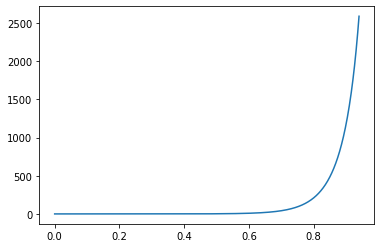

In [75]:
plt.plot(
    y,
    inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c
)

In [82]:
y = np.arange(0, 1, 0.001)
np.isnan(inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c).sum()/len(y)

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: divide by zero encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a


0.059

In [59]:
omega = parameters["omega"]
c = np.power(10, parameters["log10_c"])
tau = np.power(10, parameters["log10_tau"])
y = np.arange(0, 1, 0.001)
inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


array([4.33799248e-08, 1.61673095e-05, 3.24814110e-05, 4.90787485e-05,
       6.59108334e-05, 8.29672561e-05, 1.00341960e-04, 1.17942851e-04,
       1.35791692e-04, 1.53811373e-04, 1.72242323e-04, 1.90848582e-04,
       2.09719102e-04, 2.28900570e-04, 2.48396886e-04, 2.68069198e-04,
       2.88086374e-04, 3.08454229e-04, 3.29016845e-04, 3.49953212e-04,
       3.71142134e-04, 3.92691159e-04, 4.14512410e-04, 4.36701568e-04,
       4.59127534e-04, 4.81928805e-04, 5.05062183e-04, 5.28532513e-04,
       5.52344728e-04, 5.76503875e-04, 6.01015176e-04, 6.25883844e-04,
       6.51115051e-04, 6.76714150e-04, 7.02705682e-04, 7.29043324e-04,
       7.55781532e-04, 7.82909707e-04, 8.10433528e-04, 8.38394471e-04,
       8.66703529e-04, 8.95485896e-04, 9.24588136e-04, 9.54183420e-04,
       9.84261456e-04, 1.01469430e-03, 1.04557856e-03, 1.07694676e-03,
       1.10873355e-03, 1.14101353e-03, 1.17376189e-03, 1.20699259e-03,
       1.24073849e-03, 1.27497583e-03, 1.30964716e-03, 1.34492658e-03,
      

In [164]:
uge = (lambda x: upper_gamma_ext(-0.1, -0.1))
import warnings
warnings.filterwarnings("ignore")
inversefunc(uge, y)
warnings.filterwarnings("default")
inversefunc(uge, y)

/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: invalid value encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a
/usr/local/lib/python3.8/site-packages/pynverse/inverse.py:187: RuntimeWarning: Trouble calculating inverse for values: [0.2519872  0.79875832 0.91121327 ... 0.70304182 0.84343712 0.57589056]
  warnings.warn("Trouble calculating inverse for values: "
/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: invalid value encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a
/usr/local/lib/python3.8/site-packages/pynverse/inverse.py:194: RuntimeWarning: Results obtained with less than 2 decimal digits of accuracy
  warnings.warn("Results obtained with less than %g "


array([2.61803396, 2.61803396, 2.61803396, ..., 2.61803396, 2.61803396,
       2.61803396])

In [149]:
inverse_upper_gamma_ext(-0.1, (1 - y) * upper_gamma_ext(-omega, c / tau))

/Users/leila/git_repos/github/etas/inversion.py:168: RuntimeWarning: divide by zero encountered in power
  return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a


array([0.00022064, 0.03452557, 0.16712711, ..., 0.01143626, 0.06141043,
       0.00316765])

In [143]:
np.where((y>=0) & (y<=1), 0, 1)

array([0, 0, 0, ..., 0, 0, 0])

In [141]:
(y<=1) & (y>=0)

array([ True,  True,  True, ...,  True,  True,  True])

In [105]:
from scipy.special import gammaincc, gammainccinv

gammainccinv(1, (1 - y) * gammaincc(-omega, c / tau))

array([nan, nan, nan, ..., nan, nan, nan])

In [ ]:
aftershocks = sources.loc[sources.index.repeat(sources.n_aftershocks)]

keep_columns = ["time", "latitude", "longitude", "magnitude"]
aftershocks["parent"] = aftershocks.index

for col in keep_columns:
    aftershocks["parent_" + col] = aftershocks[col]

# time of aftershock
aftershocks = aftershocks[[col for col in aftershocks.columns if "parent" in col]].reset_index(drop=True)
aftershocks["time_delta"] = all_deltas
aftershocks.query("time_delta <= @ timewindow_length", inplace=True)

aftershocks["time"] = aftershocks["parent_time"] + pd.to_timedelta(aftershocks["time_delta"], unit='d')
aftershocks.query("time <= @ timewindow_end", inplace=True)

# location of aftershock
aftershocks["radius"] = simulate_aftershock_radius(
    parameters["log10_d"], parameters["gamma"], parameters["rho"], aftershocks["parent_magnitude"], mc=mc
)
aftershocks["angle"] = np.random.uniform(0, 2 * np.pi, size=len(aftershocks))
aftershocks["degree_lon"] = haversine(
    np.radians(aftershocks["parent_latitude"]),
    np.radians(aftershocks["parent_latitude"]),
    np.radians(0),
    np.radians(1),
    earth_radius
)
aftershocks["degree_lat"] = haversine(
    np.radians(aftershocks["parent_latitude"] - 0.5),
    np.radians(aftershocks["parent_latitude"] + 0.5),
    np.radians(0),
    np.radians(0),
    earth_radius
)
aftershocks["latitude"] = aftershocks["parent_latitude"] + (
        aftershocks["radius"] * np.cos(aftershocks["angle"])
) / aftershocks["degree_lat"]
aftershocks["longitude"] = aftershocks["parent_longitude"] + (
        aftershocks["radius"] * np.sin(aftershocks["angle"])
) / aftershocks["degree_lon"]

as_cols = [
    "parent",
    "gen_0_parent",
    "time",
    "latitude",
    "longitude"
]
if polygon is not None:
    aftershocks = gpd.GeoDataFrame(
        aftershocks,
        geometry=gpd.points_from_xy(aftershocks.latitude, aftershocks.longitude)
    )
    aftershocks = aftershocks[aftershocks.intersects(polygon)]

aadf = aftershocks[as_cols].reset_index(drop=True)

# magnitudes
n_total_aftershocks = len(aadf.index)
aadf["magnitude"] = simulate_magnitudes(n_total_aftershocks, beta=beta, mc=mc - delta_m / 2)

# info about generation and being background
aadf["generation"] = generation + 1
aadf["is_background"] = False

# info for next generation
aadf["expected_n_aftershocks"] = expected_aftershocks(
    aadf["magnitude"],
    params=[theta_without_mu, mc - delta_m / 2],
    no_start=True,
    no_end=True,
)
aadf["n_aftershocks"] = np.random.poisson(lam=aadf["expected_n_aftershocks"])

In [ ]:
# an array with all aftershocks. to be appended to the catalog
aftershocks = generate_aftershocks(
    sources, generation, parameters, beta_aftershock, mc, delta_m=delta_m,
    timewindow_end=end, timewindow_length=timewindow_length,
)

aftershocks.index += catalog.index.max() + 1

print('  number of generated aftershocks:', len(aftershocks.index))

catalog = catalog.append(aftershocks, ignore_index=False, sort=True)

generation = generation + 1

In [ ]:
while True:
    print('\n\nsimulating aftershocks of generation', generation, '..')
    sources = catalog.query("generation == @generation and n_aftershocks > 0").copy()

    # if no aftershocks are produced by events of this generation, stop
    print('  number of events with aftershocks:', len(sources.index))

    if len(sources.index) == 0:
        break

    # an array with all aftershocks. to be appended to the catalog
    aftershocks = generate_aftershocks(
        sources, generation, parameters, beta_aftershock, mc, delta_m=delta_m,
        timewindow_end=end, timewindow_length=timewindow_length,
    )

    aftershocks.index += catalog.index.max() + 1

    print('  number of generated aftershocks:', len(aftershocks.index))

    catalog = catalog.append(aftershocks, ignore_index=False, sort=True)

    generation = generation + 1

print('\n\ntotal events simulated:', len(catalog))
catalog = gpd.GeoDataFrame(catalog, geometry=gpd.points_from_xy(catalog.latitude, catalog.longitude))
catalog = catalog[catalog.intersects(polygon)]
print('inside the polygon:', len(catalog))

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


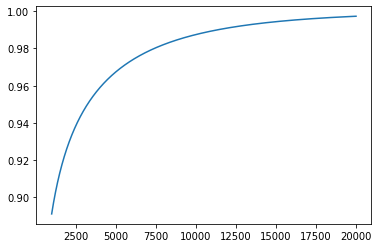

In [92]:
x = np.arange(1000, 20000, 0.01)
plt.plot(
    x,
    1 - (upper_gamma_ext(-omega, (x+c)/tau) / upper_gamma_ext(-omega, (c)/tau))
)

In [171]:
def inverse_upper_gamma_ext(a, y):
    # TODO: find a more elegant way to do this
    if a > 0:
        return gammainccinv(a, y)
    else:
        from pynverse import inversefunc
        import warnings
        
        uge = (lambda x: upper_gamma_ext(a, x))
        # numerical inverse
        def num_inv(a, y):    
            def diff(x, xhat):
                xt = upper_gamma_ext(a, x)
                return (xt - xhat)**2
            for idx,y_value in enumerate(y):
                res = minimize(diff, 1.0, args=(y_value), method='Nelder-Mead', tol=1e-6)
                x[idx] = res.x[0]

            return x

        warnings.filterwarnings("ignore")
        res = inversefunc(uge, y)
        warnings.filterwarnings("default")
        
        
        # where inversefunc was unable to calculate a result, calculate numerical approximation
        nan_idxs = np.argwhere(np.isnan(res)).flatten()
        if len(nan_idxs) > 0:
            num_res = num_inv(a, y[nan_idxs])
            res[nan_idxs] = num_res

        return res

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [170]:
a = -0.12
from pynverse import inversefunc
import warnings

uge = (lambda x: upper_gamma_ext(a, x))
# numerical inverse
def num_inv(a, y):    
    def diff(x, xhat):
        xt = upper_gamma_ext(a, x)
        return (xt - xhat)**2
    for idx,y_value in enumerate(y):
        res = minimize(diff, 1.0, args=(y_value), method='Nelder-Mead', tol=1e-6)
        x[idx] = res.x[0]

    return x

warnings.filterwarnings("ignore")
res = inversefunc(uge, y)
warnings.filterwarnings("default")


# where inversefunc was unable to calculate a result, calculate numerical approximation
nan_idxs = np.argwhere(np.isnan(res)).flatten()
if len(nan_idxs) > 0:
    num_res = num_inv(a, y[nan_idxs])
    res[nan_idxs] = num_res

res

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


array([8.41380828e+02, 4.93915249e+00, 4.36533374e+00, 4.03504667e+00,
       3.80340934e+00, 3.62541427e+00, 3.48114015e+00, 3.36001454e+00,
       3.25575404e+00, 3.16432139e+00, 3.08296938e+00, 3.00974472e+00,
       2.94320935e+00, 2.88227415e+00, 2.82609466e+00, 2.77400304e+00,
       2.72546207e+00, 2.68003339e+00, 2.63735453e+00, 2.59712247e+00,
       2.55908136e+00, 2.52301319e+00, 2.48873073e+00, 2.45607199e+00,
       2.42489595e+00, 2.39507900e+00, 2.36651228e+00, 2.33909941e+00,
       2.31275462e+00, 2.28740131e+00, 2.26297076e+00, 2.23940108e+00,
       2.21663638e+00, 2.19462595e+00, 2.17332372e+00, 2.15268770e+00,
       2.13267940e+00, 2.11326363e+00, 2.09440799e+00, 2.07608272e+00,
       2.05826026e+00, 2.04091517e+00, 2.02402386e+00, 2.00756443e+00,
       1.99151651e+00, 1.97586113e+00, 1.96058062e+00, 1.94565835e+00,
       1.93107893e+00, 1.91682778e+00, 1.90289129e+00, 1.88925668e+00,
       1.87591189e+00, 1.86284558e+00, 1.85004705e+00, 1.83750620e+00,
      

In [161]:
from scipy.optimize import minimize

y = np.arange(0,1,0.001)
x = np.zeros(y.shape)



def num_inv(a, y):
    
    def diff(x, xhat):
        xt = upper_gamma_ext(a, x)
        return (xt - xhat)**2
    for idx,y_value in enumerate(y):
        res = minimize(diff, 1.0, args=(y_value), method='Nelder-Mead', tol=1e-6)
        x[idx] = res.x[0]
        
    return x


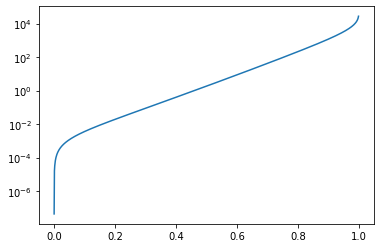

In [172]:
plt.plot(
    y,
    inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c
)
plt.yscale("log")

In [113]:
enumerate([1])